# Khmer Handwriting Recognition  

## Angle Encoding + VQC Circuit

In [7]:
import sys
from pathlib import Path

import numpy as np
from pennylane import numpy as pnp

sys.path.insert(0, str(Path("../../src").resolve()))
import quantum_model as qm  

print(f"N_LAYERS={qm.N_LAYERS}  reupload for n_qubits<={qm.REUPLOAD_MAX_QUBITS}")

N_LAYERS=10  reupload for n_qubits<=4


## Build the circuit for 4, 6 and 8 qubits — draw it, count gates and depth (Qiskit)

In [9]:
from pathlib import Path

from qiskit import QuantumCircuit

QUANTUM_MODELS_DIR = Path("../../models/quantum")
CHARTS_DIR = Path("../../results/charts/circuit")
CHARTS_DIR.mkdir(parents=True, exist_ok=True)


def build_qiskit_circuit(weights, n_qubits, n_layers, reupload):
    """Mirrors quantum_model.make_qnode()'s gate sequence exactly (readout doesn't
    affect gate structure, so this is valid regardless of what's measured)."""
    qc = QuantumCircuit(n_qubits)

    def encode():
        for q in range(n_qubits):
            qc.ry(0.0, q)  # placeholder angle -- gate count/depth don't depend on the actual value

    if not reupload:
        encode()
    for layer in range(n_layers):
        if reupload:
            encode()
        for q in range(n_qubits):
            qc.ry(float(weights[layer, q, 0]), q)
            qc.rz(float(weights[layer, q, 1]), q)
        for q in range(n_qubits):
            qc.cx(q, (q + 1) % n_qubits)
    return qc


def show_circuit_for(n_qubits):
    model_path = QUANTUM_MODELS_DIR / f"{n_qubits}q" / "best.npz"
    if model_path.exists():
        data = np.load(model_path)
        weights = data["weights"]
        n_layers = weights.shape[0]
        reupload = bool(data["reupload"]) if "reupload" in data.files else qm.default_reupload(n_qubits)
    else:
        n_layers = qm.N_LAYERS
        weights = np.array(qm.init_weights(n_qubits, n_layers=n_layers, seed=0))
        reupload = qm.default_reupload(n_qubits)

    qc = build_qiskit_circuit(weights, n_qubits, n_layers, reupload)
    print(f"{n_qubits} qubits, {n_layers} layers, reupload={reupload} -> "
          f"gate count={qc.size()}, depth={qc.depth()}")

    fig = qc.draw("mpl", fold=30)
    fig.savefig(CHARTS_DIR / f"qiskit_circuit_{n_qubits}q.png", dpi=150, bbox_inches="tight")
    display(fig)

4 qubits, 10 layers, reupload=True -> gate count=160, depth=70


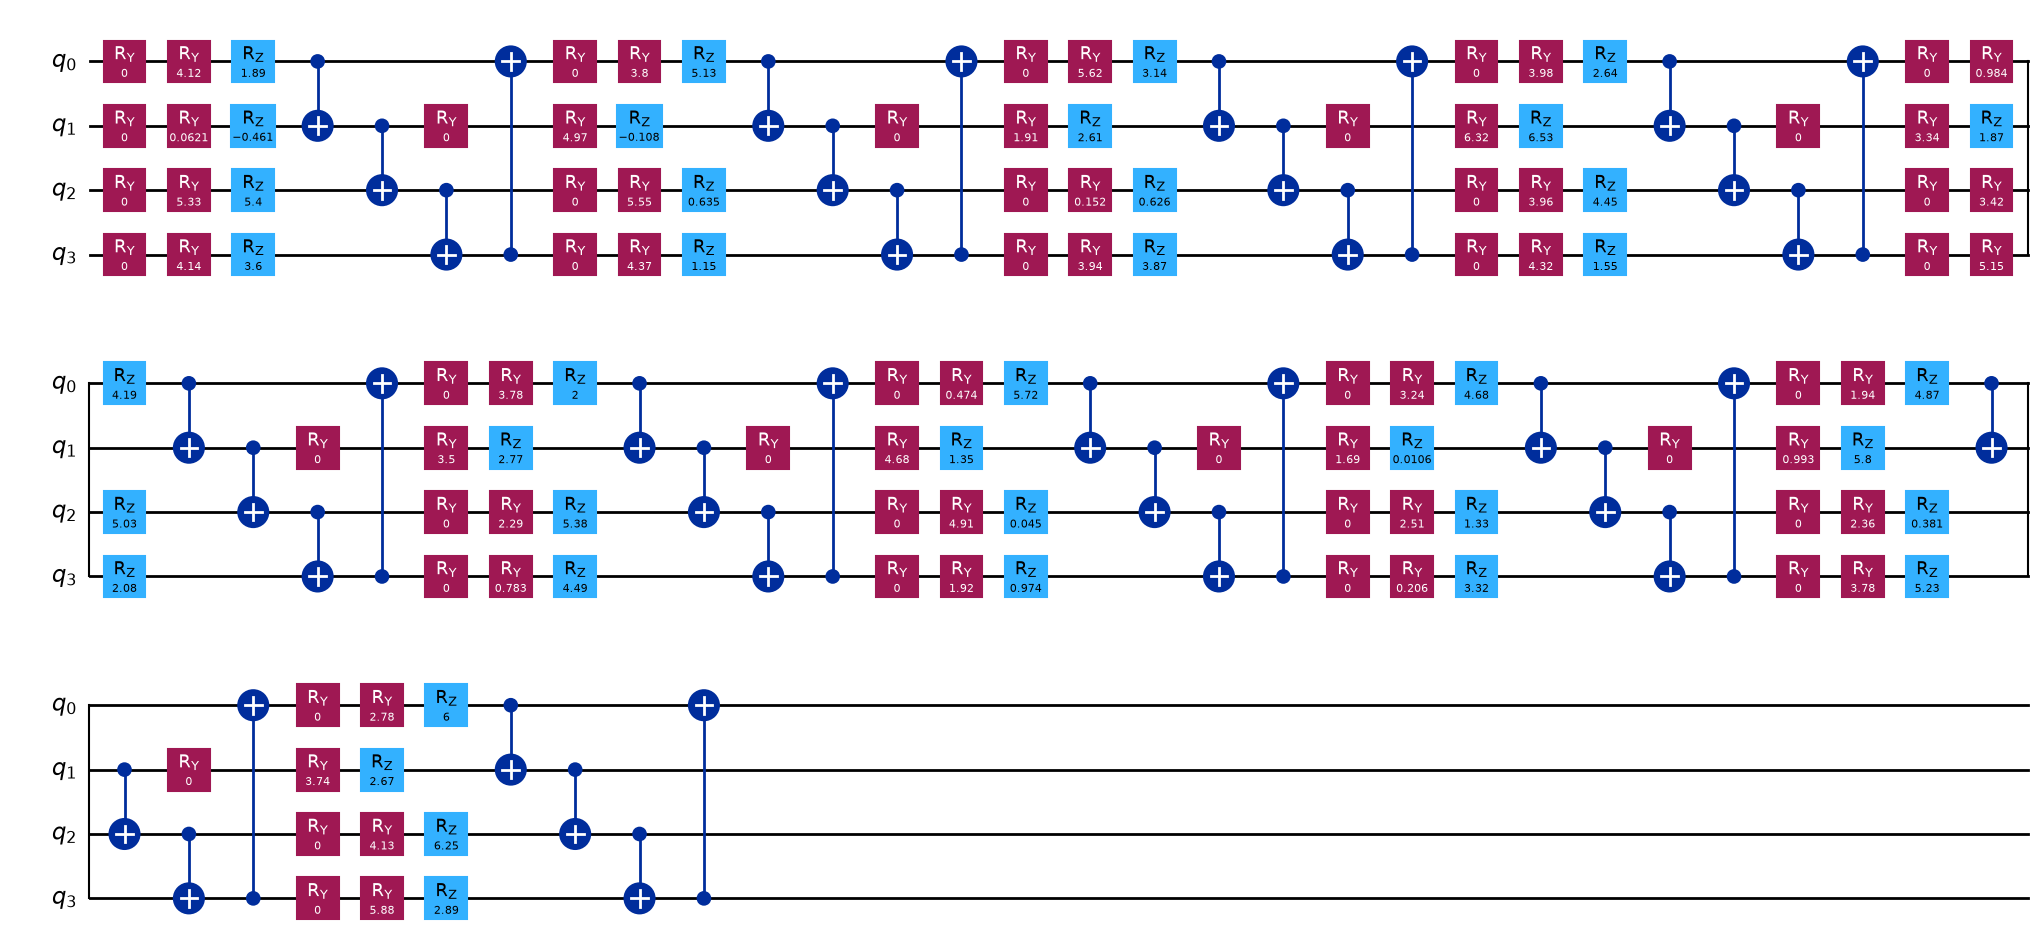

In [10]:
show_circuit_for(4)

6 qubits, 10 layers, reupload=False -> gate count=186, depth=81


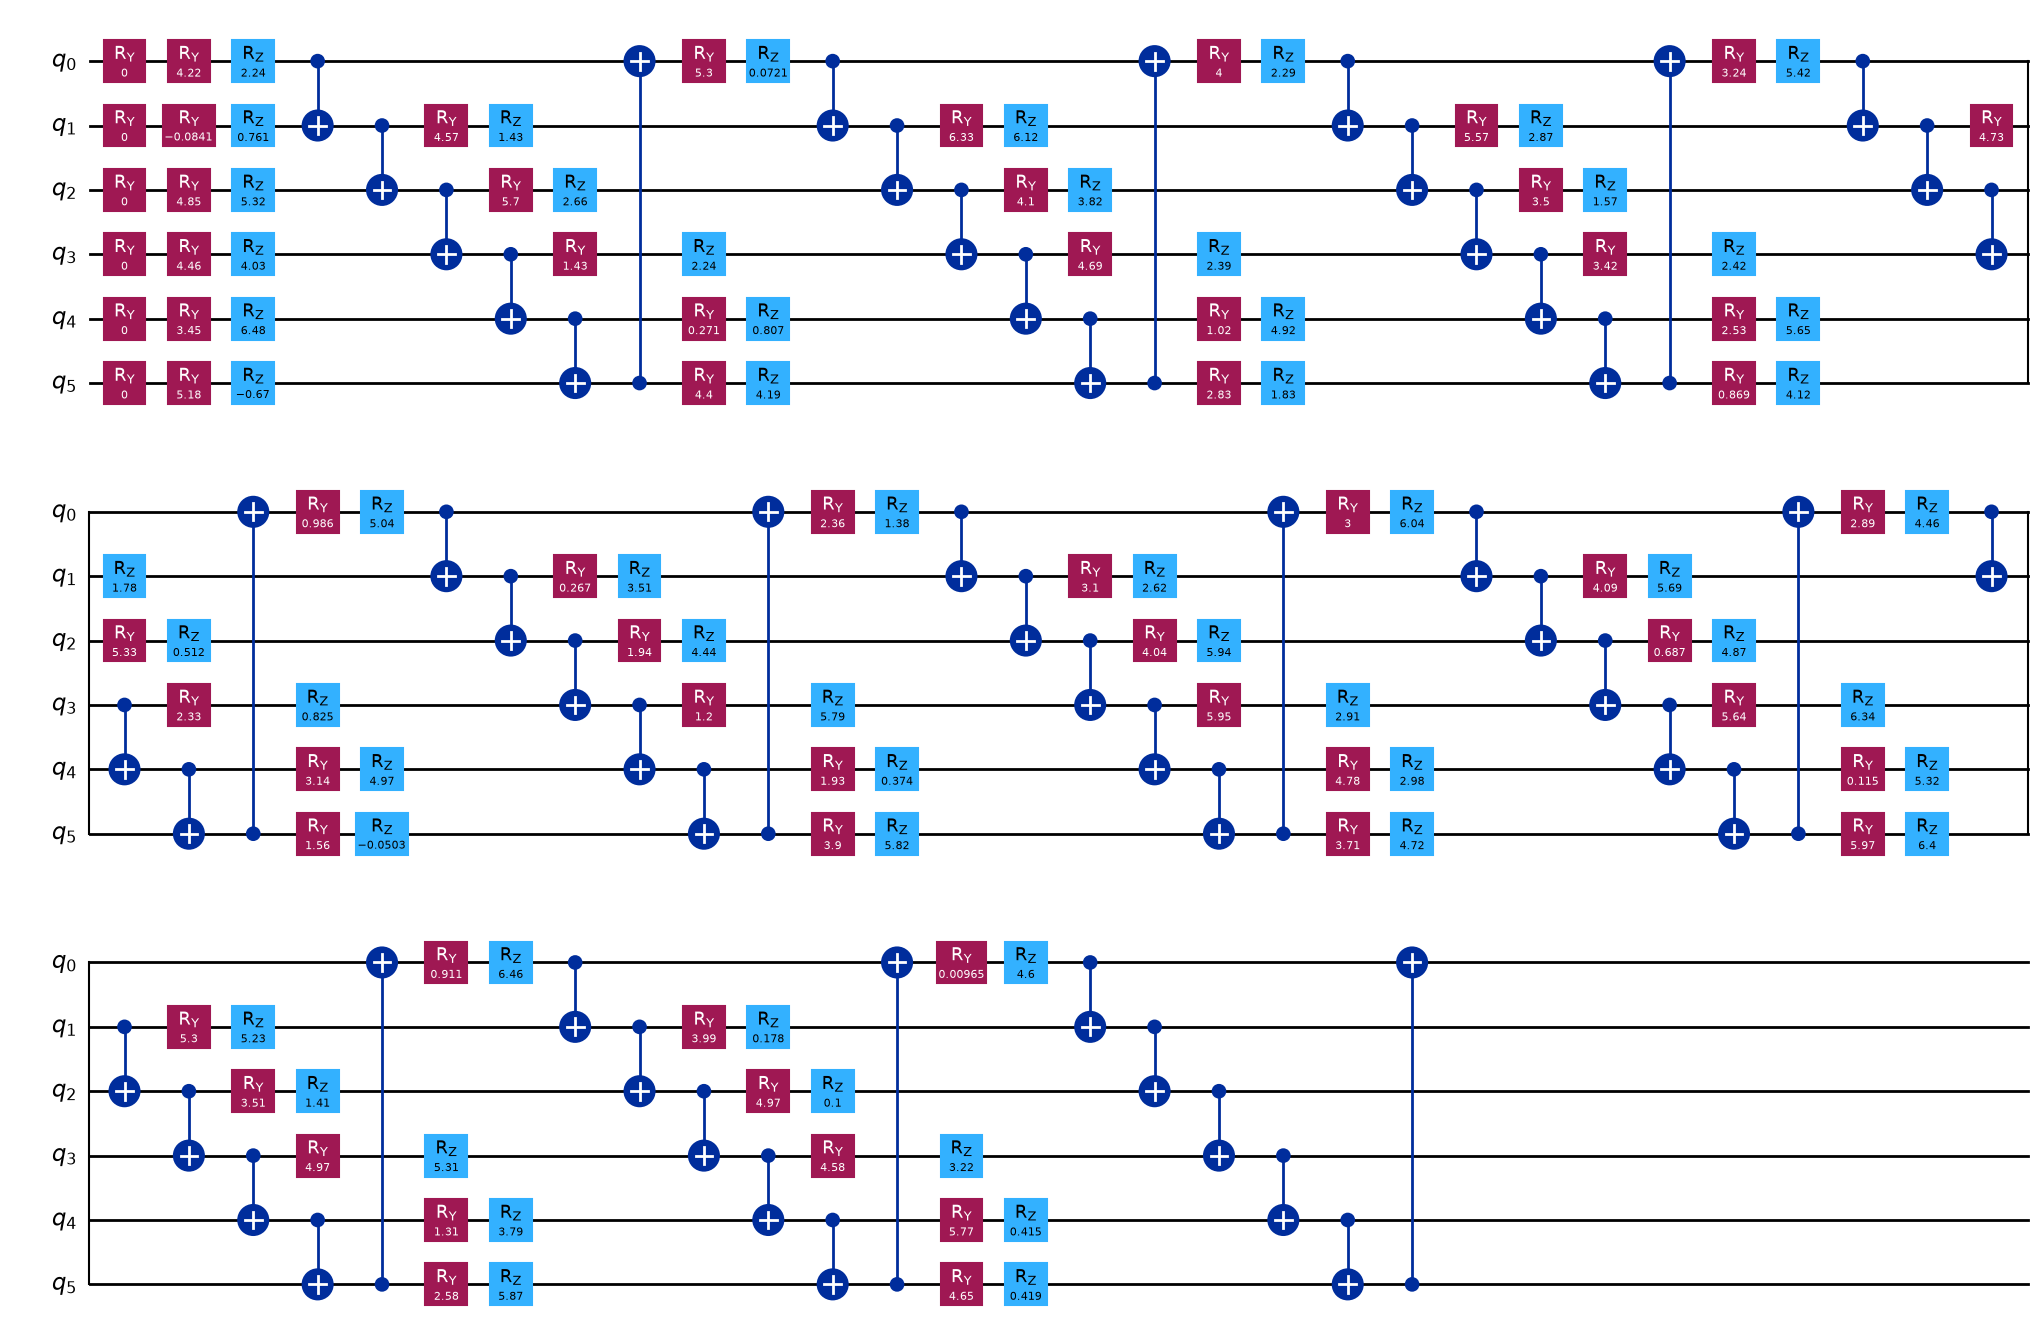

In [11]:
show_circuit_for(6)

8 qubits, 10 layers, reupload=False -> gate count=248, depth=101


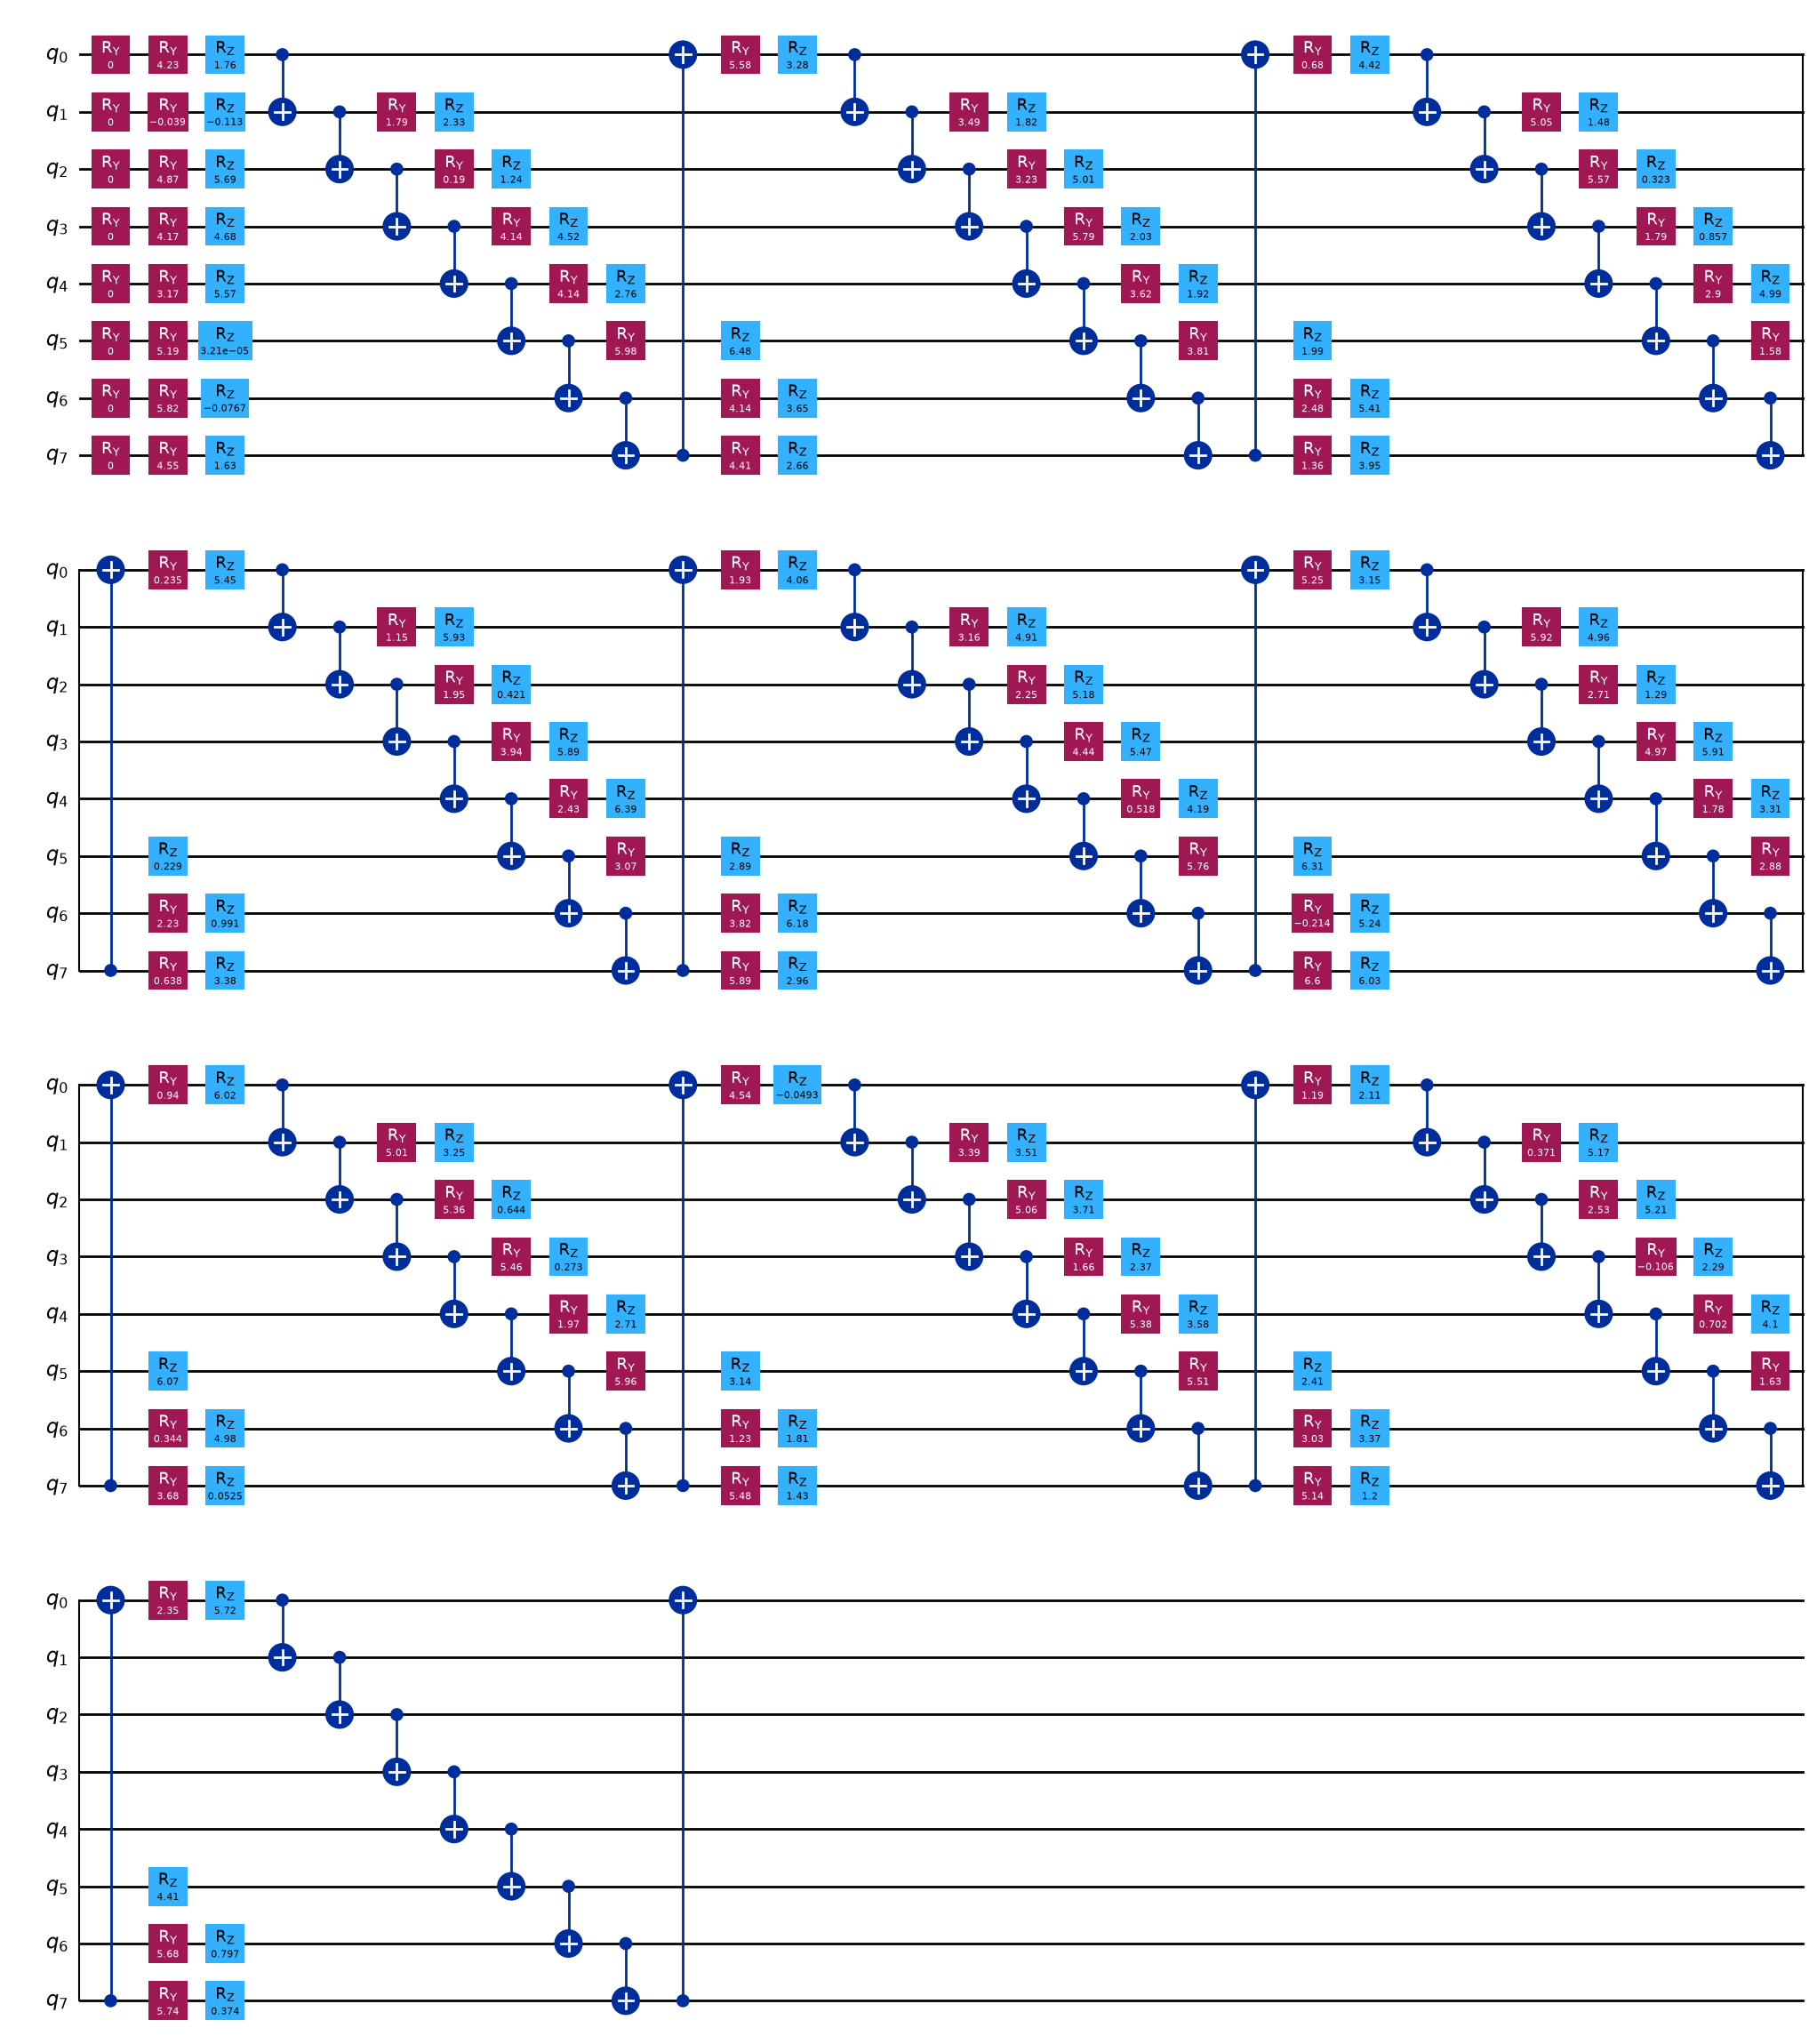

In [12]:
show_circuit_for(8)